In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = r"..\..\data\raw\ev_charging_dataset.xlsx"

stations = pd.read_excel(file_path, sheet_name="stations")
chargers = pd.read_excel(file_path, sheet_name="chargers")
sessions = pd.read_excel(file_path, sheet_name="sessions")

print("STATIONS:", stations.shape)
print("CHARGERS:", chargers.shape)
print("SESSIONS:", sessions.shape)

print("\n--- Station Columns ---")
print(stations.columns.tolist())

print("\n--- Station Information ---")
display(stations.head())
display(stations.info())

print("\n--- Available Regions ---")
print(sessions["station_region"].value_counts())

print("\n--- Missing Values in Stations ---")
print(stations.isnull().sum())


STATIONS: (33, 5)
CHARGERS: (199, 5)
SESSIONS: (294024, 15)

--- Station Columns ---
['station_id', 'station_name', 'region', 'activation_year', 'n_chargers']

--- Station Information ---


,station_id,station_name,region,activation_year,n_chargers
0,STN_001,EV FastCharge 1,North West,2022,4
1,STN_002,EV FastCharge 2,London,2022,5
2,STN_003,EV FastCharge 3,Midlands,2022,5
3,STN_004,EV FastCharge 4,North West,2022,8
4,STN_005,EV FastCharge 5,North West,2022,8


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   station_id       33 non-null     object
 1   station_name     33 non-null     object
 2   region           33 non-null     object
 3   activation_year  33 non-null     int64 
 4   n_chargers       33 non-null     int64 
dtypes: int64(2), object(3)
memory usage: 1.4+ KB


None


--- Available Regions ---
station_region
North West            65789
Midlands              50598
London                40760
North East            30439
South West            30401
South East            25168
Yorkshire & Humber    20468
Scotland              20242
Wales                 10159
Name: count, dtype: int64

--- Missing Values in Stations ---
station_id         0
station_name       0
region             0
activation_year    0
n_chargers         0
dtype: int64


In [2]:
# Check whether station IDs match across datasets
print("Unique stations in sessions:", sessions["station_id"].nunique())
print("Unique stations in station dataset:", stations["station_id"].nunique())

# Compare regional labels between sessions and stations
region_check = sessions.merge(
    stations[["station_id", "region"]],
    on="station_id",
    how="left"
)

region_check["region_match"] = (
    region_check["station_region"] == region_check["region"]
)

print("\nMissing station matches:", region_check["region"].isna().sum())
print("Region mismatches:", (~region_check["region_match"]).sum())

# Check whether every station has charging sessions
stations_without_sessions = stations[
    ~stations["station_id"].isin(sessions["station_id"])
]

print("\nStations without sessions:")
display(stations_without_sessions)

Unique stations in sessions: 33
Unique stations in station dataset: 33

Missing station matches: 0
Region mismatches: 0

Stations without sessions:


,station_id,station_name,region,activation_year,n_chargers


In [3]:
# 1. Aggregate charging demand by region
regional_demand = (
    sessions.groupby("station_region")
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("energy_kwh", "sum"),
        total_revenue=("total_cost", "sum"),
        avg_energy_per_session=("energy_kwh", "mean")
    )
    .reset_index()
)

# 2. Aggregate infrastructure by region
regional_infrastructure = (
    stations.groupby("region")
    .agg(
        total_stations=("station_id", "nunique"),
        total_chargers=("n_chargers", "sum")
    )
    .reset_index()
)

# 3. Combine demand and infrastructure
regional_analysis = regional_demand.merge(
    regional_infrastructure,
    left_on="station_region",
    right_on="region",
    how="left"
)

# 4. Calculate demand per infrastructure unit
regional_analysis["sessions_per_charger"] = (
    regional_analysis["total_sessions"] /
    regional_analysis["total_chargers"]
)

regional_analysis["energy_per_charger"] = (
    regional_analysis["total_energy_kwh"] /
    regional_analysis["total_chargers"]
)

# 5. Sort by total energy demand
regional_analysis = regional_analysis.sort_values(
    "total_energy_kwh",
    ascending=False
)

display(regional_analysis.round(2))

,station_region,total_sessions,total_energy_kwh,total_revenue,avg_energy_per_session,region,total_stations,total_chargers,sessions_per_charger,energy_per_charger
3,North West,65789,3005135.1,1749659.79,45.68,North West,7,48,1370.60,62606.98
1,Midlands,50598,2576709.8,1512888.72,50.93,Midlands,5,26,1946.08,99104.22
0,London,40760,1978090.6,1167892.57,48.53,London,5,25,1630.40,79123.62
6,South West,30401,1580496.2,936566.78,51.99,South West,3,15,2026.73,105366.41
2,North East,30439,1398050.3,827839.36,45.93,North East,3,17,1790.53,82238.25
5,South East,25168,1088495.1,650189.40,43.25,South East,4,26,968.00,41865.20
4,Scotland,20242,947010.5,568971.33,46.78,Scotland,3,22,920.09,43045.93
8,Yorkshire & Humber,20468,899734.0,551615.57,43.96,Yorkshire & Humber,2,12,1705.67,74977.83
7,Wales,10159,335024.2,205476.60,32.98,Wales,1,8,1269.88,41878.02


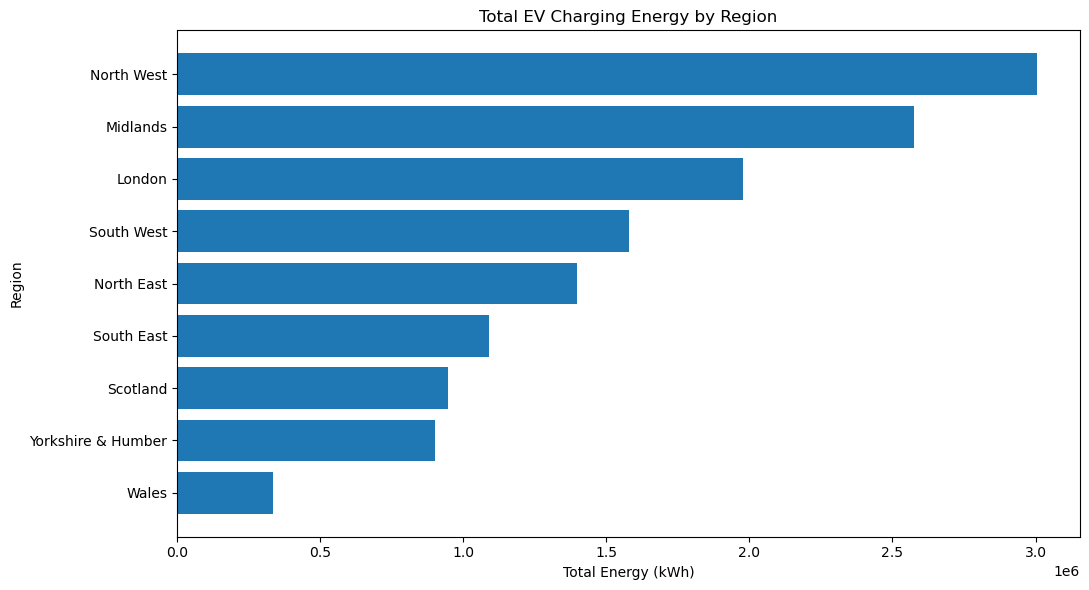

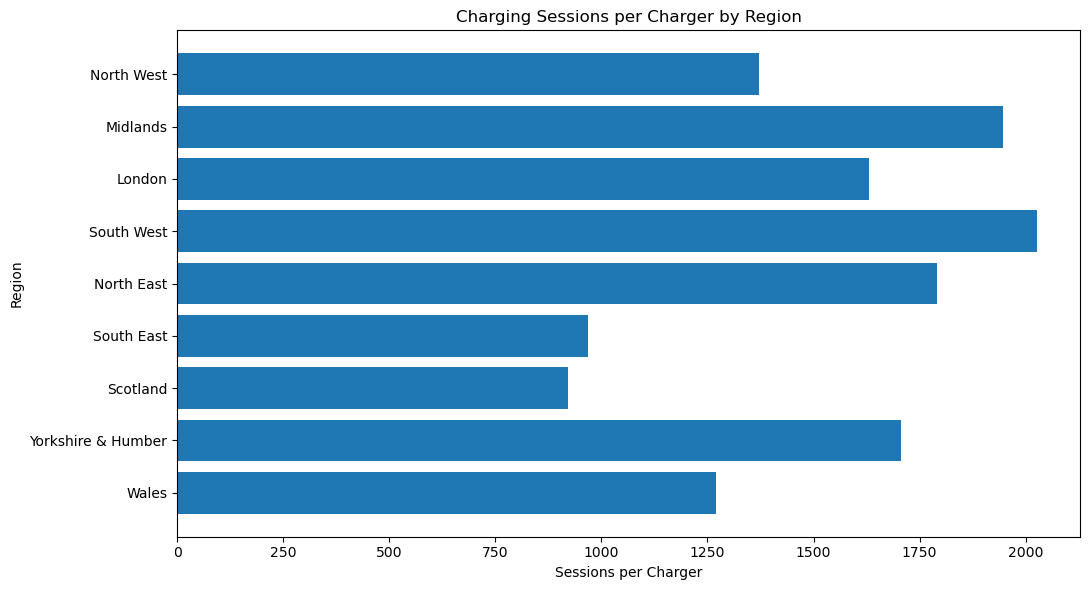

In [4]:
# Sort regions by total energy demand
plot_data = regional_analysis.sort_values(
    "total_energy_kwh",
    ascending=True
)

# Chart 1: Total energy demand by region
plt.figure(figsize=(11, 6))

plt.barh(
    plot_data["station_region"],
    plot_data["total_energy_kwh"]
)

plt.title("Total EV Charging Energy by Region")
plt.xlabel("Total Energy (kWh)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


# Chart 2: Sessions per charger
plt.figure(figsize=(11, 6))

plt.barh(
    plot_data["station_region"],
    plot_data["sessions_per_charger"]
)

plt.title("Charging Sessions per Charger by Region")
plt.xlabel("Sessions per Charger")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

In [5]:
# Convert session timestamps to datetime
sessions["start_timestamp"] = pd.to_datetime(
    sessions["start_timestamp"]
)

# Extract year and month
sessions["year_month"] = (
    sessions["start_timestamp"].dt.to_period("M")
)

# Calculate monthly energy demand for each region
monthly_regional_demand = (
    sessions.groupby(["year_month", "station_region"])
    .agg(
        total_sessions=("session_id", "count"),
        total_energy_kwh=("energy_kwh", "sum")
    )
    .reset_index()
)

# Convert year_month to string for easier plotting
monthly_regional_demand["year_month"] = (
    monthly_regional_demand["year_month"].astype(str)
)

display(monthly_regional_demand.head())
print("\nShape:", monthly_regional_demand.shape)

,year_month,station_region,total_sessions,total_energy_kwh
0,2022-01,London,434,26435.6
1,2022-01,Midlands,841,43242.3
2,2022-01,North East,431,18621.9
3,2022-01,North West,1267,57029.7
4,2022-01,South West,421,21836.8



Shape: (276, 4)


In [6]:
# Count months available for each region
monthly_coverage = (
    monthly_regional_demand.groupby("station_region")
    .agg(
        months_available=("year_month", "nunique"),
        first_month=("year_month", "min"),
        last_month=("year_month", "max")
    )
    .reset_index()
)

display(monthly_coverage)

# Check missing region-month combinations
expected_months = pd.period_range(
    start="2022-01",
    end="2024-12",
    freq="M"
).astype(str)

all_regions = sessions["station_region"].unique()

expected_combinations = pd.MultiIndex.from_product(
    [expected_months, all_regions],
    names=["year_month", "station_region"]
).to_frame(index=False)

coverage_check = expected_combinations.merge(
    monthly_regional_demand,
    on=["year_month", "station_region"],
    how="left"
)

missing_combinations = coverage_check[
    coverage_check["total_sessions"].isna()
]

print("Expected records:", len(expected_combinations))
print("Actual records:", len(monthly_regional_demand))
print("Missing region-month combinations:", len(missing_combinations))

display(missing_combinations.head(20))

,station_region,months_available,first_month,last_month
0,London,36,2022-01,2024-12
1,Midlands,36,2022-01,2024-12
2,North East,36,2022-01,2024-12
3,North West,36,2022-01,2024-12
4,Scotland,24,2023-01,2024-12
5,South East,24,2023-01,2024-12
6,South West,36,2022-01,2024-12
7,Wales,24,2023-01,2024-12
8,Yorkshire & Humber,24,2023-01,2024-12


Expected records: 324
Actual records: 276
Missing region-month combinations: 48


,year_month,station_region,total_sessions,total_energy_kwh
5,2022-01,Wales,NaN,NaN
6,2022-01,Scotland,NaN,NaN
7,2022-01,Yorkshire & Humber,NaN,NaN
8,2022-01,South East,NaN,NaN
14,2022-02,Wales,NaN,NaN
15,2022-02,Scotland,NaN,NaN
16,2022-02,Yorkshire & Humber,NaN,NaN
17,2022-02,South East,NaN,NaN
23,2022-03,Wales,NaN,NaN
24,2022-03,Scotland,NaN,NaN


In [7]:
# Extract year from year_month
monthly_regional_demand["year"] = (
    monthly_regional_demand["year_month"].str[:4].astype(int)
)

# Compare annual regional demand for 2023 and 2024
annual_regional_demand = (
    monthly_regional_demand[
        monthly_regional_demand["year"].isin([2023, 2024])
    ]
    .groupby(["station_region", "year"])
    .agg(
        total_sessions=("total_sessions", "sum"),
        total_energy_kwh=("total_energy_kwh", "sum")
    )
    .reset_index()
)

# Convert years into separate columns
regional_growth = annual_regional_demand.pivot(
    index="station_region",
    columns="year",
    values=["total_sessions", "total_energy_kwh"]
)

# Flatten column names
regional_growth.columns = [
    f"{metric}_{year}" for metric, year in regional_growth.columns
]

regional_growth = regional_growth.reset_index()

# Calculate percentage growth
regional_growth["session_growth_pct"] = (
    (regional_growth["total_sessions_2024"] -
     regional_growth["total_sessions_2023"]) /
    regional_growth["total_sessions_2023"] * 100
)

regional_growth["energy_growth_pct"] = (
    (regional_growth["total_energy_kwh_2024"] -
     regional_growth["total_energy_kwh_2023"]) /
    regional_growth["total_energy_kwh_2023"] * 100
)

regional_growth = regional_growth.sort_values(
    "energy_growth_pct",
    ascending=False
)

display(regional_growth.round(2))

,station_region,total_sessions_2023,total_sessions_2024,total_energy_kwh_2023,total_energy_kwh_2024,session_growth_pct,energy_growth_pct
5,South East,5113.0,20055.0,204037.4,884457.7,292.24,333.48
4,Scotland,5090.0,15152.0,234426.5,712584.0,197.68,203.97
3,North West,15200.0,35544.0,683071.8,1645815.7,133.84,140.94
0,London,10103.0,25524.0,548892.3,1113599.5,152.64,102.88
1,Midlands,15123.0,25180.0,755365.5,1285571.7,66.50,70.19
2,North East,9976.0,15344.0,452497.8,721819.5,53.81,59.52
6,South West,10180.0,15173.0,552525.3,767494.9,49.05,38.91
8,Yorkshire & Humber,10236.0,10232.0,449767.5,449966.5,-0.04,0.04
7,Wales,5111.0,5048.0,168540.4,166483.8,-1.23,-1.22


In [8]:
# Select relevant 2024 demand and growth metrics
expansion_analysis = regional_growth[
    [
        "station_region",
        "total_sessions_2024",
        "total_energy_kwh_2024",
        "energy_growth_pct",
        "session_growth_pct"
    ]
].copy()

# Add infrastructure information
expansion_analysis = expansion_analysis.merge(
    regional_infrastructure,
    left_on="station_region",
    right_on="region",
    how="left"
)

# Calculate 2024 demand per charger
expansion_analysis["sessions_per_charger_2024"] = (
    expansion_analysis["total_sessions_2024"] /
    expansion_analysis["total_chargers"]
)

expansion_analysis["energy_per_charger_2024"] = (
    expansion_analysis["total_energy_kwh_2024"] /
    expansion_analysis["total_chargers"]
)

# Sort by 2024 energy demand per charger
expansion_analysis = expansion_analysis.sort_values(
    "energy_per_charger_2024",
    ascending=False
)

display(
    expansion_analysis[
        [
            "station_region",
            "total_stations",
            "total_chargers",
            "total_energy_kwh_2024",
            "energy_growth_pct",
            "energy_per_charger_2024",
            "sessions_per_charger_2024"
        ]
    ].round(2)
)

,station_region,total_stations,total_chargers,total_energy_kwh_2024,energy_growth_pct,energy_per_charger_2024,sessions_per_charger_2024
6,South West,3,15,767494.9,38.91,51166.33,1011.53
4,Midlands,5,26,1285571.7,70.19,49445.07,968.46
3,London,5,25,1113599.5,102.88,44543.98,1020.96
5,North East,3,17,721819.5,59.52,42459.97,902.59
7,Yorkshire & Humber,2,12,449966.5,0.04,37497.21,852.67
2,North West,7,48,1645815.7,140.94,34287.83,740.50
0,South East,4,26,884457.7,333.48,34017.60,771.35
1,Scotland,3,22,712584.0,203.97,32390.18,688.73
8,Wales,1,8,166483.8,-1.22,20810.47,631.00


In [9]:
# Create percentile ranks for the three indicators
scored_regions = expansion_analysis.copy()

scored_regions["infrastructure_pressure_score"] = (
    scored_regions["energy_per_charger_2024"].rank(pct=True)
)

scored_regions["growth_score"] = (
    scored_regions["energy_growth_pct"].rank(pct=True)
)

scored_regions["demand_score"] = (
    scored_regions["total_energy_kwh_2024"].rank(pct=True)
)

# Equal weighting for the initial exploratory score
scored_regions["expansion_priority_score"] = (
    scored_regions["infrastructure_pressure_score"] * 0.40 +
    scored_regions["growth_score"] * 0.30 +
    scored_regions["demand_score"] * 0.30
) * 100

# Rank regions by overall score
scored_regions = scored_regions.sort_values(
    "expansion_priority_score",
    ascending=False
)

display(
    scored_regions[
        [
            "station_region",
            "infrastructure_pressure_score",
            "growth_score",
            "demand_score",
            "expansion_priority_score"
        ]
    ].round(3)
)

,station_region,infrastructure_pressure_score,growth_score,demand_score,expansion_priority_score
4,Midlands,0.889,0.556,0.889,78.889
3,London,0.778,0.667,0.778,74.444
2,North West,0.444,0.778,1.000,71.111
6,South West,1.000,0.333,0.556,66.667
0,South East,0.333,1.000,0.667,63.333
5,North East,0.667,0.444,0.444,53.333
1,Scotland,0.222,0.889,0.333,45.556
7,Yorkshire & Humber,0.556,0.222,0.222,35.556
8,Wales,0.111,0.111,0.111,11.111


In [10]:
# Compare different weighting assumptions
sensitivity = scored_regions[
    [
        "station_region",
        "infrastructure_pressure_score",
        "growth_score",
        "demand_score"
    ]
].copy()

# Scenario 1: Infrastructure-focused
sensitivity["infrastructure_focused"] = (
    sensitivity["infrastructure_pressure_score"] * 0.50 +
    sensitivity["growth_score"] * 0.25 +
    sensitivity["demand_score"] * 0.25
) * 100

# Scenario 2: Balanced
sensitivity["balanced"] = (
    sensitivity["infrastructure_pressure_score"] / 3 +
    sensitivity["growth_score"] / 3 +
    sensitivity["demand_score"] / 3
) * 100

# Scenario 3: Growth-focused
sensitivity["growth_focused"] = (
    sensitivity["infrastructure_pressure_score"] * 0.25 +
    sensitivity["growth_score"] * 0.50 +
    sensitivity["demand_score"] * 0.25
) * 100

# Compare regional rankings
for scenario in [
    "infrastructure_focused",
    "balanced",
    "growth_focused"
]:
    sensitivity[f"{scenario}_rank"] = (
        sensitivity[scenario].rank(
            ascending=False,
            method="min"
        ).astype(int)
    )

sensitivity = sensitivity.sort_values(
    "balanced",
    ascending=False
)

display(
    sensitivity[
        [
            "station_region",
            "infrastructure_focused_rank",
            "balanced_rank",
            "growth_focused_rank"
        ]
    ]
)

,station_region,infrastructure_focused_rank,balanced_rank,growth_focused_rank
4,Midlands,1,1,3
3,London,2,2,3
2,North West,4,2,1
0,South East,5,4,1
6,South West,3,5,6
5,North East,6,6,7
1,Scotland,7,7,5
7,Yorkshire & Humber,8,8,8
8,Wales,9,9,9


In [11]:
from pathlib import Path

# Create output folders
output_dir = Path("analysis")
output_dir.mkdir(parents=True, exist_ok=True)

# Final regional recommendation table
final_recommendations = scored_regions[
    [
        "station_region",
        "total_stations",
        "total_chargers",
        "total_energy_kwh_2024",
        "energy_growth_pct",
        "energy_per_charger_2024",
        "sessions_per_charger_2024",
        "expansion_priority_score"
    ]
].copy()

final_recommendations["priority_rank"] = (
    final_recommendations["expansion_priority_score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

final_recommendations = final_recommendations.sort_values(
    "priority_rank"
)

# Save outputs
regional_analysis.to_csv(
    output_dir / "regional_demand_infrastructure.csv",
    index=False
)

regional_growth.to_csv(
    output_dir / "regional_demand_growth.csv",
    index=False
)

final_recommendations.to_csv(
    output_dir / "regional_expansion_recommendations.csv",
    index=False
)

sensitivity.to_csv(
    output_dir / "scoring_sensitivity_analysis.csv",
    index=False
)

display(final_recommendations.round(2))

print("\nAnalysis outputs saved successfully.")

,station_region,total_stations,total_chargers,total_energy_kwh_2024,energy_growth_pct,energy_per_charger_2024,sessions_per_charger_2024,expansion_priority_score,priority_rank
4,Midlands,5,26,1285571.7,70.19,49445.07,968.46,78.89,1
3,London,5,25,1113599.5,102.88,44543.98,1020.96,74.44,2
2,North West,7,48,1645815.7,140.94,34287.83,740.50,71.11,3
6,South West,3,15,767494.9,38.91,51166.33,1011.53,66.67,4
0,South East,4,26,884457.7,333.48,34017.60,771.35,63.33,5
5,North East,3,17,721819.5,59.52,42459.97,902.59,53.33,6
1,Scotland,3,22,712584.0,203.97,32390.18,688.73,45.56,7
7,Yorkshire & Humber,2,12,449966.5,0.04,37497.21,852.67,35.56,8
8,Wales,1,8,166483.8,-1.22,20810.47,631.00,11.11,9



Analysis outputs saved successfully.
